# Modelo de difusión basado en score — VE-SDE en MNIST

Notebook principal para entrenar y evaluar el modelo de difusión del TFG.

Se mantiene la implementación original basada en **Variance Exploding SDE (VE-SDE)** y `ScoreNet`, pero se reorganiza siguiendo la misma estructura utilizada en los notebooks de PCD y DSM: el notebook contiene la configuración y los experimentos, mientras que la implementación se encuentra en los módulos del proyecto.

## 1. Imports

In [ ]:
import sys
from pathlib import Path

project_root = Path.cwd().parents[0]
sys.path.append(str(project_root))

print("Project root:", project_root)

import time
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

from data import get_mnist_loaders

from diffusion.score_models import ScoreNet
from diffusion.processes import VEProcess
from diffusion.samplers import euler_maruyama_integrator
from diffusion.training import train_diffusion_model
from diffusion.noise_schedules import compute_effective_noise_trajectory
from utils import (
    plot_image_grid,
    plot_image_evolution,
    sample_initial_latents,
)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("device:", device)

Project root: /home/usuario/Documentos/TFG
device: cuda


## 2. Configuración

Se conserva la configuración principal del experimento original: VE-SDE con `sigma=25`, Adam con `lr=1e-3` y 30 épocas. Para MNIST se utilizan imágenes de un solo canal en `[0, 1]`.

In [4]:
QUICK_TEST = False

CFG = {
    "seed": 42,
    "batch_size": 32,
    "lr": 1e-3,
    "epochs": 30,

    # VE-SDE
    "sigma": 25.0,

    # muestreo
    "t_start": 1.0 - 1e-3,
    "t_end": 1e-3,
    "n_steps": 2000,
    "n_corrector_steps": 3,
    "corrector_step_size": 1e-4,

    # guardado
    "ckpt_dir": str(project_root / "diffusion" / "checkpoints"),
    "results_dir": str(project_root / "diffusion" / "results"),
}

if QUICK_TEST:
    CFG["epochs"] = 1
    CFG["n_steps"] = 100

set_seed(CFG["seed"])

CFG

{'seed': 42,
 'batch_size': 32,
 'lr': 0.001,
 'epochs': 30,
 'sigma': 25.0,
 't_start': 0.999,
 't_end': 0.001,
 'n_steps': 2000,
 'n_corrector_steps': 3,
 'corrector_step_size': 0.0001,
 'ckpt_dir': '/home/usuario/Documentos/TFG/diffusion/checkpoints',
 'results_dir': '/home/usuario/Documentos/TFG/diffusion/results'}

## 3. Datos MNIST

A diferencia del notebook original, se utiliza **todo MNIST** y no únicamente un dígito. Las imágenes se mantienen en `[0, 1]`, igual que en DSM.

shape: torch.Size([32, 1, 28, 28])
min: 0.0
max: 1.0


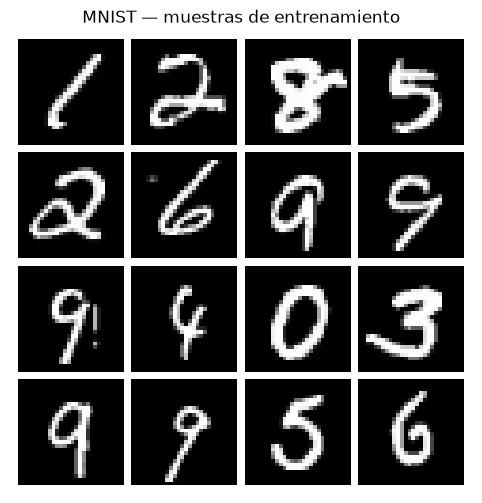

In [5]:
train_loader, test_loader = get_mnist_loaders(
    batch_size=CFG["batch_size"],
    normalize=False,
    num_workers=2,
)

train_ds = train_loader.dataset
test_ds = test_loader.dataset

x_real, y_real = next(iter(train_loader))

print("shape:", x_real.shape)
print("min:", x_real.min().item())
print("max:", x_real.max().item())

fig, ax = plot_image_grid(
    images=x_real[:16],
    figsize=(6, 6),
    n_cols=4,
)

ax.set_title("MNIST — muestras de entrenamiento")
plt.show()

## 4. Proceso de difusión — VE-SDE

Se utiliza el proceso `VEProcess` del experimento original. El nivel de ruido depende continuamente del tiempo mediante `sigma_t(t)`.

In [6]:
diffusion_process = VEProcess(
    sigma=CFG["sigma"],
)

print("sigma:", CFG["sigma"])

for t_value in [0.0, 0.25, 0.5, 0.75, 1.0]:
    t = torch.tensor([t_value], device=device)
    print(
        f"t={t_value:.2f} | "
        f"sigma_t={diffusion_process.sigma_t(t).item():.4f}"
    )

sigma: 25.0
t=0.00 | sigma_t=0.0000
t=0.25 | sigma_t=0.7882
t=0.50 | sigma_t=1.9308
t=0.75 | sigma_t=4.3888
t=1.00 | sigma_t=9.8452


## 5. Red de score

Se utiliza la `ScoreNet` original condicionada en el tiempo. Para MNIST la entrada tiene un único canal.

In [7]:
set_seed(CFG["seed"])

score_model = ScoreNet(
    marginal_prob_std=diffusion_process.sigma_t,
    in_channels=1,
).to(device)

n_parameters = sum(
    parameter.numel()
    for parameter in score_model.parameters()
    if parameter.requires_grad
)

print(f"Parámetros entrenables: {n_parameters:,}")

Parámetros entrenables: 1,115,297


## 6. Entrenamiento

El bucle de entrenamiento se encuentra en `diffusion/training/train_diffusion_model.py`, de la misma forma que el entrenamiento de PCD y DSM se encuentra fuera de sus notebooks.

In [ ]:
optimizer = torch.optim.Adam(
    score_model.parameters(),
    lr=CFG["lr"],
)

hist_it = {
    "loss": [],
}

hist_ep = {
    "epoch": [],
    "loss": [],
    "loss_per_t": [],
    "time_s": [],
}

In [ ]:
hist_it, hist_ep = train_diffusion_model(
    model=score_model,
    diffusion_process=diffusion_process,
    data_loader=train_loader,
    optimizer=optimizer,
    device=device,
    config=CFG,
    hist_it=hist_it,
    hist_ep=hist_ep,
)

época   1/30 |   14.7s | loss   93.2686
época   2/30 |   14.2s | loss   31.0868
época   3/30 |   14.4s | loss   25.3001


## 7. Curvas de entrenamiento

In [ ]:
def smooth(values, window=100):
    values = np.asarray(values, dtype=float)

    if len(values) < window:
        return values

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid",
    )


fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

ax[0].plot(
    smooth(hist_it["loss"])
)
ax[0].set_xlabel("iteración")
ax[0].set_ylabel("loss")
ax[0].set_title("Pérdida por iteración")

ax[1].plot(
    hist_ep["epoch"],
    hist_ep["loss"],
    marker="o",
)
ax[1].set_xlabel("época")
ax[1].set_ylabel("loss media")
ax[1].set_title("Pérdida por época")

plt.tight_layout()
plt.show()

In [ ]:
loss_per_t = np.array(
    hist_ep["loss_per_t"]
)

t_centers = (
    np.arange(10)
    + 0.5
) / 10

plt.figure(figsize=(7, 5))

plt.plot(
    t_centers,
    loss_per_t[-1],
    marker="o",
)

plt.xlabel("t")
plt.ylabel("Loss")
plt.title(
    "Loss por intervalo temporal "
    "(última época)"
)
plt.grid()

plt.show()

## 8. Generación con Predictor-Corrector

Se conserva el muestreador Predictor-Corrector utilizado en el notebook original. La trayectoria completa se guarda para poder analizar la evolución de las imágenes durante el proceso inverso.

In [ ]:
N_IMAGES = 8

set_seed(123)

image_T = sample_initial_latents(
    n_images=N_IMAGES,
    image_shape=(1, 28, 28),
    mean=0.0,
    std=1.0,
    device=device,
)

start = time.time()

with torch.no_grad():
    times, synthetic_images_t = euler_maruyama_integrator(
        image_T,
        t_0=CFG["t_start"],
        t_end=CFG["t_end"],
        n_steps=CFG["n_steps"],
        drift_coefficient=lambda x_t, t: diffusion_process.reverse_drift(
            x_t,
            t,
            score_model,
        ),
        diffusion_coefficient=diffusion_process.diffusion_coefficient

    )

elapsed = time.time() - start

print(
    f"{N_IMAGES} muestras generadas en {elapsed:.1f}s"
)
print("trajectory shape:", synthetic_images_t.shape)

In [ ]:
step_indices = np.linspace(
    0,
    len(times) - 1,
    50,
    dtype=int,
)

times_diag, effective_noise = (
    compute_effective_noise_trajectory(
        model=score_model,
        diffusion_process=diffusion_process,
        times=times,
        trajectory=synthetic_images_t ,
        step_indices=step_indices,
    )
)

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    times_diag,
    effective_noise,
    marker="o",
)

plt.xlabel("t")
plt.ylabel("Magnitud normalizada")
plt.title(
    "Magnitud de la corrección del score "
    "durante el muestreo"
)

plt.grid()

plt.show()

## 9. Evolución del proceso inverso

In [ ]:
steps_to_show = [
    0,
    5,
    200,
    300,
    400,
    500,
    1000,
    1500,
    1800,
    CFG["n_steps"],
]

steps_to_show = [
    step
    for step in steps_to_show
    if step <= CFG["n_steps"]
]

_ = plot_image_evolution(
    images=synthetic_images_t.cpu(),
    n_images=N_IMAGES,
    n_intermediate_steps=steps_to_show,
    figsize=(12, 10),
)

## 10. Muestras finales

In [ ]:
# La última posición temporal corresponde al final del proceso inverso.
final_samples = synthetic_images_t[..., -1]

fig, ax = plot_image_grid(
    images=final_samples.cpu(),
    figsize=(7, 7),
    n_cols=4,
)

ax.set_title(
    "VE-SDE — muestras finales con Predictor-Corrector"
)

plt.show()